# Olist E-commerce: Customer, Delivery & Retention Analysis

**Data:** ~99k orders placed on Olist, a Brazilian marketplace, Sep 2016 - Sep 2018 (9 linked tables).

**Business questions**
1. How is the business growing, and when do people buy?
2. Do customers come back? Which customers matter most (RFM)?
3. What drives bad reviews? Is it the product or the delivery?
4. Which categories, sellers and regions need attention?

The SQL layer (`sql/`) does the heavy aggregation; this notebook reads those results,
adds statistics and segmentation, and saves the charts used in the README and Excel dashboard.

In [1]:
from pathlib import Path
import sqlite3
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
try:
    ROOT = Path(__file__).resolve().parents[1]
except NameError:          # running inside the notebook (cwd = notebooks/)
    ROOT = Path.cwd().resolve().parent
DB = ROOT / "data" / "olist.db"
RES = ROOT / "outputs" / "sql_results"
FIG = ROOT / "reports" / "figures"
PROC = ROOT / "data" / "processed"
FIG.mkdir(parents=True, exist_ok=True)
PROC.mkdir(parents=True, exist_ok=True)

INK, MUTED, ACCENT, BAD, GOOD = "#1f2937", "#9ca3af", "#2563eb", "#dc2626", "#059669"
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "figure.dpi": 110})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show() if "ipykernel" in __import__("sys").modules else plt.close(fig)

r = lambda name: pd.read_csv(RES / f"{name}.csv")
con = sqlite3.connect(DB)
orders = pd.read_sql_query("SELECT * FROM v_orders", con, parse_dates=["order_purchase_timestamp"])
kpi = r("kpi_summary").iloc[0]
print(f"{int(kpi.total_orders):,} orders | {int(kpi.unique_customers):,} customers | "
      f"R$ {kpi.gross_revenue/1e6:.2f}M revenue | AOV R$ {kpi.avg_order_value:.0f} | "
      f"avg review {kpi.avg_review_score} | {kpi.pct_late_of_delivered}% delivered late")

98,207 orders | 94,990 customers | R$ 15.74M revenue | AOV R$ 160 | avg review 4.12 | 6.77% delivered late


## 1. Growth and buying patterns

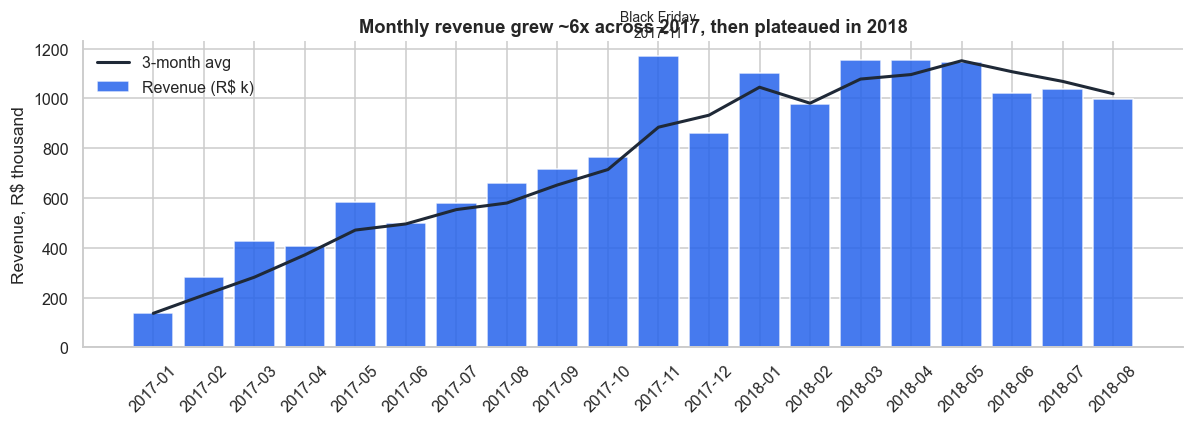

Jan-Aug revenue: 2017 R$ 3.57M -> 2018 R$ 8.59M  (+140%)


In [2]:
m = r("monthly_trend")
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(m.purchase_month, m.revenue / 1e3, color=ACCENT, alpha=.85, label="Revenue (R$ k)")
ax.plot(m.purchase_month, m.revenue_3m_avg / 1e3, color=INK, lw=2, label="3-month avg")
ax.set_ylabel("Revenue, R$ thousand")
ax.set_title("Monthly revenue grew ~6x across 2017, then plateaued in 2018")
peak = m.loc[m.revenue.idxmax()]
ax.annotate(f"Black Friday\n{peak.purchase_month}", (peak.purchase_month, peak.revenue / 1e3),
            xytext=(0, 12), textcoords="offset points", ha="center", fontsize=9)
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="upper left", frameon=False)
save(fig, "01_monthly_revenue")

g17 = m[m.purchase_month.between("2017-01", "2017-08")].revenue.sum()
g18 = m[m.purchase_month.between("2018-01", "2018-08")].revenue.sum()
print(f"Jan-Aug revenue: 2017 R$ {g17/1e6:.2f}M -> 2018 R$ {g18/1e6:.2f}M  (+{100*(g18/g17-1):.0f}%)")

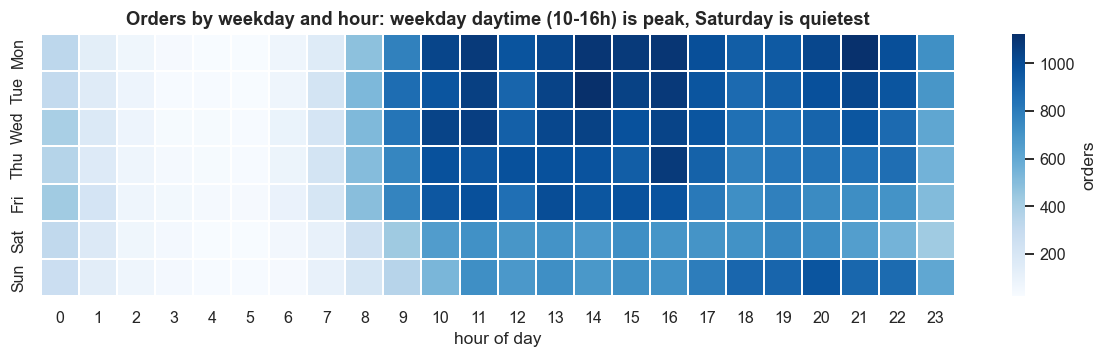

In [3]:
h = r("weekday_hour_heatmap").pivot(index="weekday", columns="hour", values="orders")
h = h.loc[["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]]
fig, ax = plt.subplots(figsize=(11, 3.4))
sns.heatmap(h, cmap="Blues", ax=ax, cbar_kws={"label": "orders"}, linewidths=.3)
ax.set_title("Orders by weekday and hour: weekday daytime (10-16h) is peak, Saturday is quietest")
ax.set_xlabel("hour of day"); ax.set_ylabel(""); ax.grid(False)
save(fig, "02_weekday_hour_heatmap")

## 2. Retention: almost nobody comes back

`customer_id` changes with every order, so all retention work uses `customer_unique_id`.

orders_per_customer  customers  pct_customers    revenue  pct_revenue
                  1      92102          96.96 14845269.0        94.34
                  2       2652           2.79   771940.0         4.91
                  3        188           0.20    80933.0         0.51
                 4+         48           0.05    37385.0         0.24


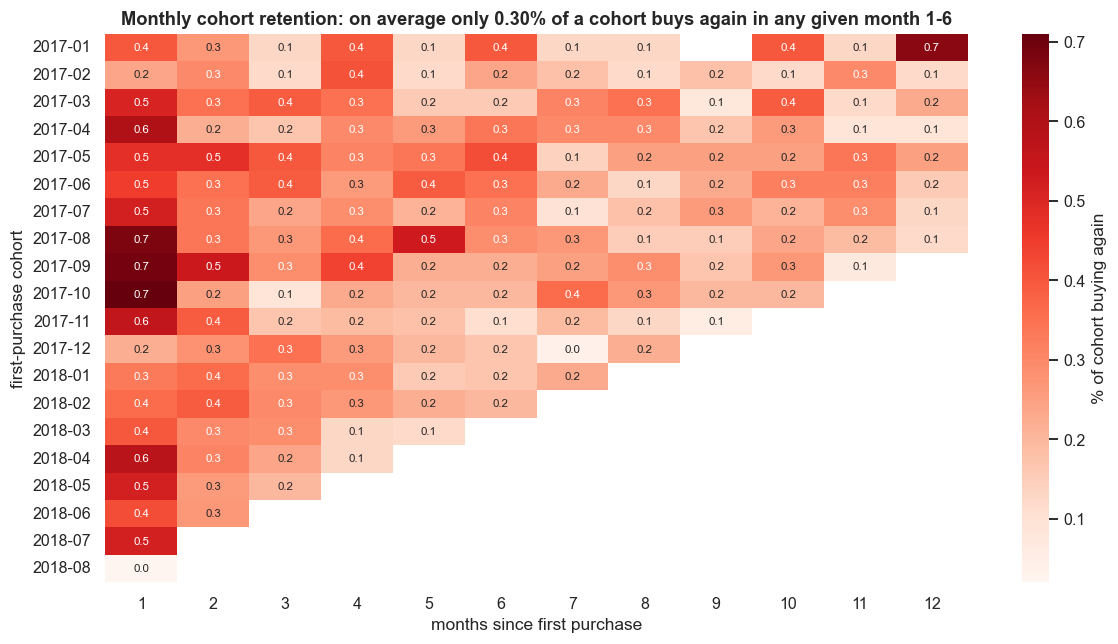

In [4]:
rep = r("repeat_purchase_distribution")
print(rep.to_string(index=False))
coh = r("cohort_retention")
piv = coh.pivot(index="cohort", columns="month_n", values="retention_pct")
avg_m1_to_m6 = piv.loc[:, 1:6].mean().mean()

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(piv.loc[:, 1:12], annot=True, fmt=".1f", cmap="Reds", ax=ax,
            cbar_kws={"label": "% of cohort buying again"}, annot_kws={"size": 7.5})
ax.set_title(f"Monthly cohort retention: on average only {avg_m1_to_m6:.2f}% of a cohort buys again in any given month 1-6")
ax.set_xlabel("months since first purchase"); ax.set_ylabel("first-purchase cohort"); ax.grid(False)
save(fig, "03_cohort_retention")

### RFM segmentation
Scores and segments are computed in SQL (`sql/05_rfm_segmentation.sql`), one row per customer.
**R** and **M** are data-driven quintiles; **F** uses business logic (1 / 2 / 3+ orders) because ~97% of
customers buy once. The cut-offs below come straight from the data.

reference_date  customers    revenue
    2018-09-04      94983 15735527.0
                         metric  score  min_value  max_value  customers
             Frequency (orders)      1       1.00       1.00      92096
             Frequency (orders)      2       2.00       2.00       2651
             Frequency (orders)      3       3.00      16.00        236
      Monetary (R$ total spend)      1       9.59      55.36      18997
      Monetary (R$ total spend)      2      55.36      87.50      18997
      Monetary (R$ total spend)      3      87.51     133.05      18997
      Monetary (R$ total spend)      4     133.05     209.11      18996
      Monetary (R$ total spend)      5     209.11   13664.08      18996
Recency (days since last order)      1     389.00     730.00      18996
Recency (days since last order)      2     274.00     389.00      18996
Recency (days since last order)      3     183.00     274.00      18997
Recency (days since last order)      4      99.00     183.00  

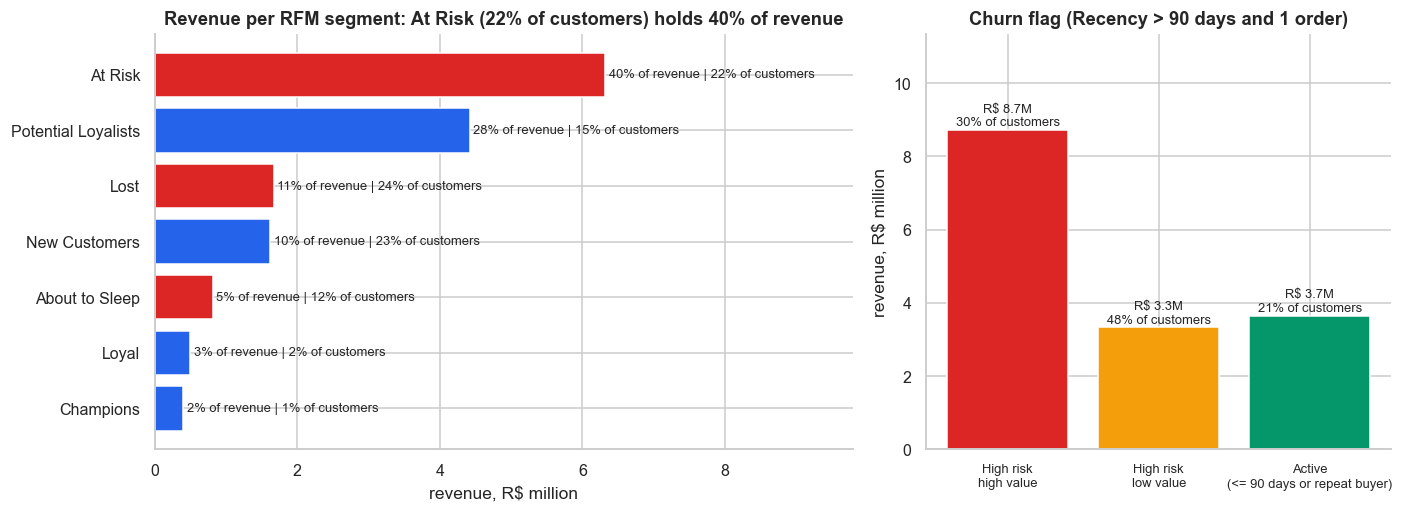

In [5]:
print(r("rfm_reference").to_string(index=False))
print(r("rfm_cutoffs").to_string(index=False))

seg = r("rfm_segment_summary").set_index("segment")
ACTIONS = {
    "Champions": "VIP perks, referral programme, early access to launches",
    "Loyal": "Personalised win-back offers in their favourite categories",
    "Potential Loyalists": "Second-order coupon within 30 days of delivery",
    "New Customers": "Onboarding emails, cross-sell bundles, free-shipping threshold nudges",
    "At Risk": "High-touch win-back: personalised offer + survey on why they left",
    "About to Sleep": "Low-cost email reactivation before they become Lost",
    "Lost": "Suppress from paid channels; seasonal campaigns only",
}
seg["recommended_action"] = seg.index.map(ACTIONS)
seg.reset_index().to_csv(PROC / "rfm_segment_summary.csv", index=False, lineterminator="\n")
print(seg[["customers", "pct_customers", "revenue", "pct_revenue", "avg_spend", "avg_recency_days"]].to_string())

churn = r("rfm_churn_risk")
churn["tier"] = churn.churn_risk_tier.str[2:]
print(churn[["tier", "customers", "pct_customers", "revenue", "pct_revenue"]].to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
s2 = seg.sort_values("revenue")
colors = [BAD if i in ("At Risk", "About to Sleep", "Lost") else ACCENT for i in s2.index]
axes[0].barh(s2.index, s2.revenue / 1e6, color=colors)
for i, (rev, pr, pc) in enumerate(zip(s2.revenue, s2.pct_revenue, s2.pct_customers)):
    axes[0].text(rev / 1e6 + .05, i, f"{pr:.0f}% of revenue | {pc:.0f}% of customers", va="center", fontsize=8.5)
axes[0].set_xlim(0, s2.revenue.max() / 1e6 * 1.55)
axes[0].set_xlabel("revenue, R$ million")
top = seg.iloc[0]
axes[0].set_title(f"Revenue per RFM segment: {seg.index[0]} ({top.pct_customers:.0f}% of customers) holds {top.pct_revenue:.0f}% of revenue")
axes[1].bar(churn.tier.str.replace(" - ", "\n").str.replace(" (", "\n("), churn.revenue / 1e6,
            color=[BAD, "#f59e0b", GOOD])
for i, (rev, pc) in enumerate(zip(churn.revenue, churn.pct_customers)):
    axes[1].text(i, rev / 1e6 + .1, f"R$ {rev/1e6:.1f}M\n{pc:.0f}% of customers", ha="center", fontsize=8.5)
axes[1].set_ylim(0, churn.revenue.max() / 1e6 * 1.3)
axes[1].set_ylabel("revenue, R$ million")
axes[1].set_title("Churn flag (Recency > 90 days and 1 order)")
axes[1].tick_params(axis="x", labelsize=8.5)
save(fig, "04_rfm_segments")

## 3. What drives bad reviews? Delivery.

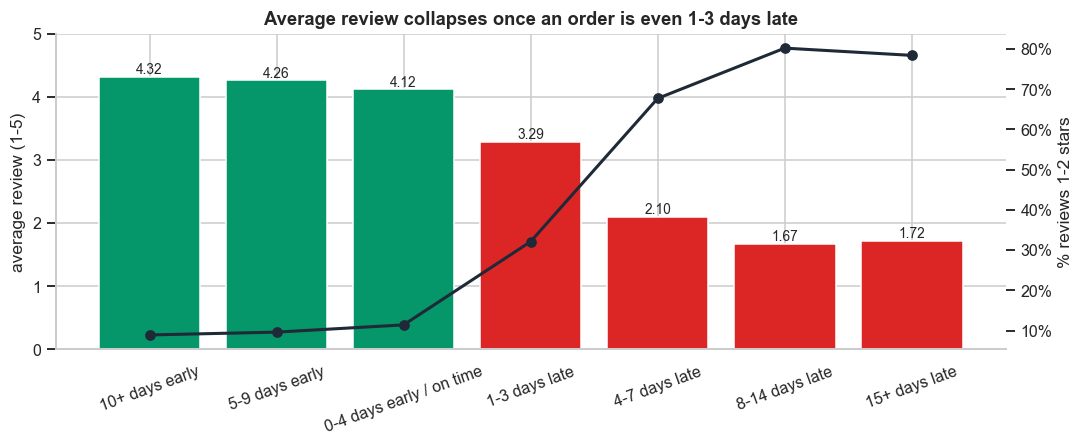

On-time avg 4.29 vs late avg 2.27; Mann-Whitney U p = 0.0e+00


In [6]:
d = r("review_by_delivery_delay")
d["band"] = d.delay_band.str[2:]
fig, ax1 = plt.subplots(figsize=(10, 4.2))
colors = [GOOD if "early" in b else BAD for b in d.band]
ax1.bar(d.band, d.avg_review, color=colors)
for i, v in enumerate(d.avg_review):
    ax1.text(i, v + .05, f"{v:.2f}", ha="center", fontsize=9)
ax1.set_ylim(0, 5); ax1.set_ylabel("average review (1-5)")
ax1.set_title("Average review collapses once an order is even 1-3 days late")
ax1.tick_params(axis="x", rotation=20)
ax2 = ax1.twinx()
ax2.plot(d.band, d.pct_negative, color=INK, marker="o", lw=2)
ax2.set_ylabel("% reviews 1-2 stars"); ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.grid(False)
save(fig, "05_review_vs_delay")

dl = orders[(orders.is_delivered == 1) & orders.review_score.notna()]
late, ontime = dl[dl.is_late == 1].review_score, dl[dl.is_late == 0].review_score
u, p = stats.mannwhitneyu(late, ontime, alternative="less")
print(f"On-time avg {ontime.mean():.2f} vs late avg {late.mean():.2f}; Mann-Whitney U p = {p:.1e}")

### Which factors predict a 1-2 star review?
A simple, interpretable logistic regression on delivered orders. Standardised coefficients show
the relative pull of each driver.

Test ROC-AUC 0.742


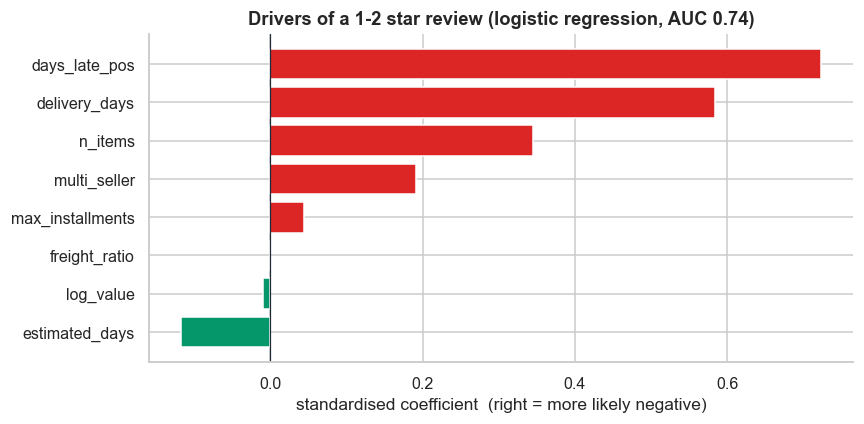

In [7]:
X = dl.assign(
    days_late_pos=dl.days_late.clip(lower=0),
    multi_seller=(dl.n_sellers > 1).astype(int),
    freight_ratio=dl.freight_value / dl.items_value.replace(0, np.nan),
    log_value=np.log1p(dl.gross_value),
)
feats = ["days_late_pos", "delivery_days", "estimated_days", "multi_seller", "n_items",
         "freight_ratio", "log_value", "max_installments"]
X = X.dropna(subset=feats)
y = (X.review_score <= 2).astype(int)
Xtr, Xte, ytr, yte = train_test_split(X[feats], y, test_size=.25, random_state=42, stratify=y)
sc = StandardScaler().fit(Xtr)
lr = LogisticRegression(max_iter=1000, class_weight="balanced").fit(sc.transform(Xtr), ytr)
auc = roc_auc_score(yte, lr.predict_proba(sc.transform(Xte))[:, 1])
coef = pd.Series(lr.coef_[0], index=feats).sort_values()
coef.rename("std_coef").to_csv(PROC / "negative_review_drivers.csv", lineterminator="\n")
print(f"Test ROC-AUC {auc:.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(coef.index, coef.values, color=[BAD if v > 0 else GOOD for v in coef.values])
ax.axvline(0, color=INK, lw=.8)
ax.set_title(f"Drivers of a 1-2 star review (logistic regression, AUC {auc:.2f})")
ax.set_xlabel("standardised coefficient  (right = more likely negative)")
save(fig, "06_negative_review_drivers")

## 4. Regions, categories and sellers

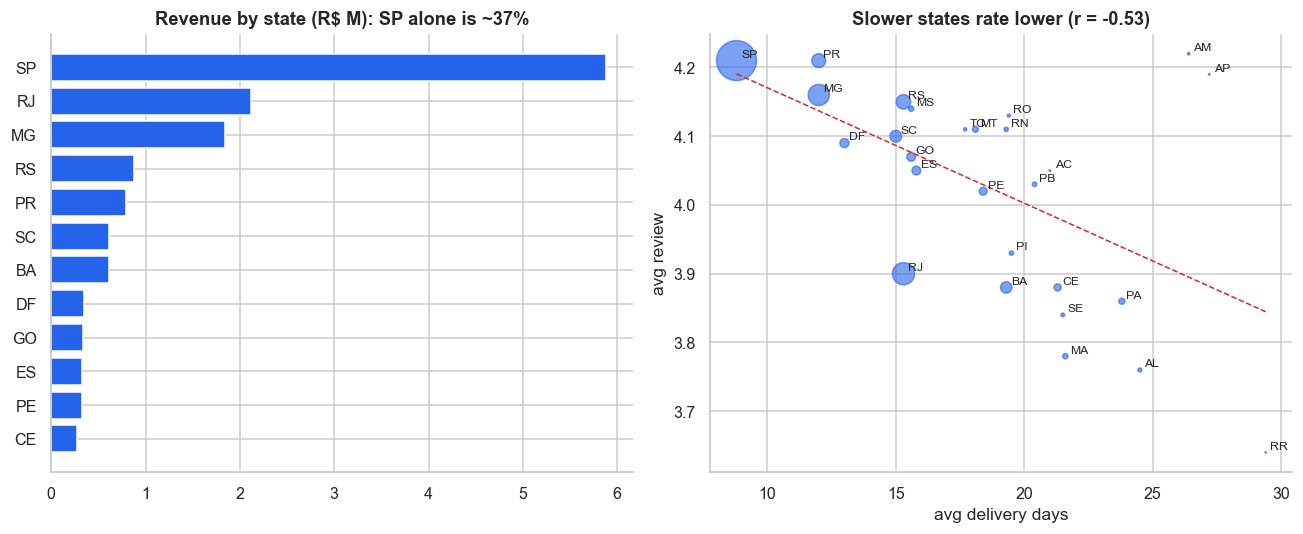

In [8]:
st = r("customers_by_state")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
top = st.nlargest(12, "revenue").sort_values("revenue")
axes[0].barh(top.customer_state, top.revenue / 1e6, color=ACCENT)
axes[0].set_title("Revenue by state (R$ M): SP alone is ~37%")
axes[1].scatter(st.avg_delivery_days, st.avg_review, s=st.orders / 60, color=ACCENT, alpha=.6)
for _, row in st.iterrows():
    axes[1].annotate(row.customer_state, (row.avg_delivery_days, row.avg_review), fontsize=8,
                     xytext=(3, 2), textcoords="offset points")
slope, icpt, rv, pv, _ = stats.linregress(st.avg_delivery_days, st.avg_review)
xs = np.linspace(st.avg_delivery_days.min(), st.avg_delivery_days.max(), 10)
axes[1].plot(xs, icpt + slope * xs, color=BAD, ls="--", lw=1)
axes[1].set_xlabel("avg delivery days"); axes[1].set_ylabel("avg review")
axes[1].set_title(f"Slower states rate lower (r = {rv:.2f})")
save(fig, "07_states")

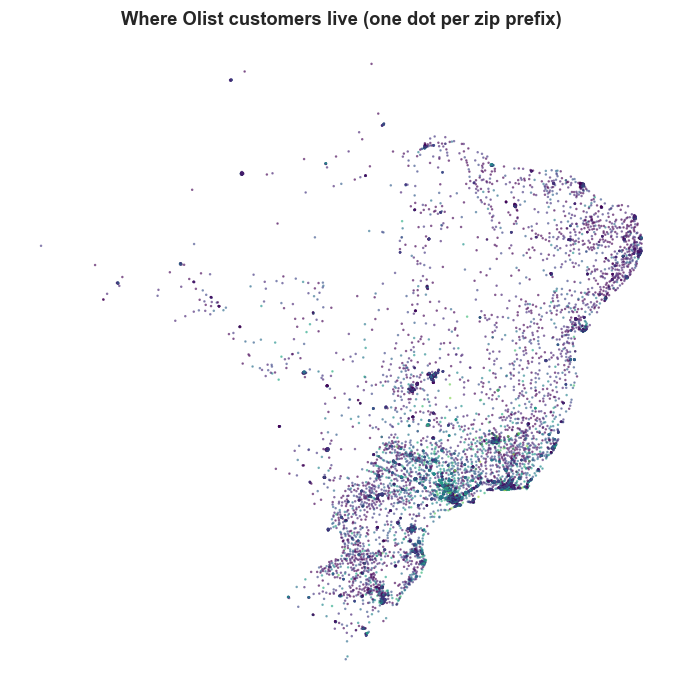

In [9]:
geo = pd.read_sql_query("""
    SELECT g.lat, g.lng, COUNT(*) AS orders
    FROM orders o JOIN customers c ON c.customer_id = o.customer_id
    JOIN geolocation g ON g.zip_code_prefix = c.customer_zip_code_prefix
    GROUP BY g.lat, g.lng""", con)
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(geo.lng, geo.lat, s=.4, c=np.log1p(geo.orders), cmap="viridis", alpha=.6)
ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
for sp in ax.spines.values(): sp.set_visible(False)
ax.set_title("Where Olist customers live (one dot per zip prefix)")
save(fig, "08_customer_map")

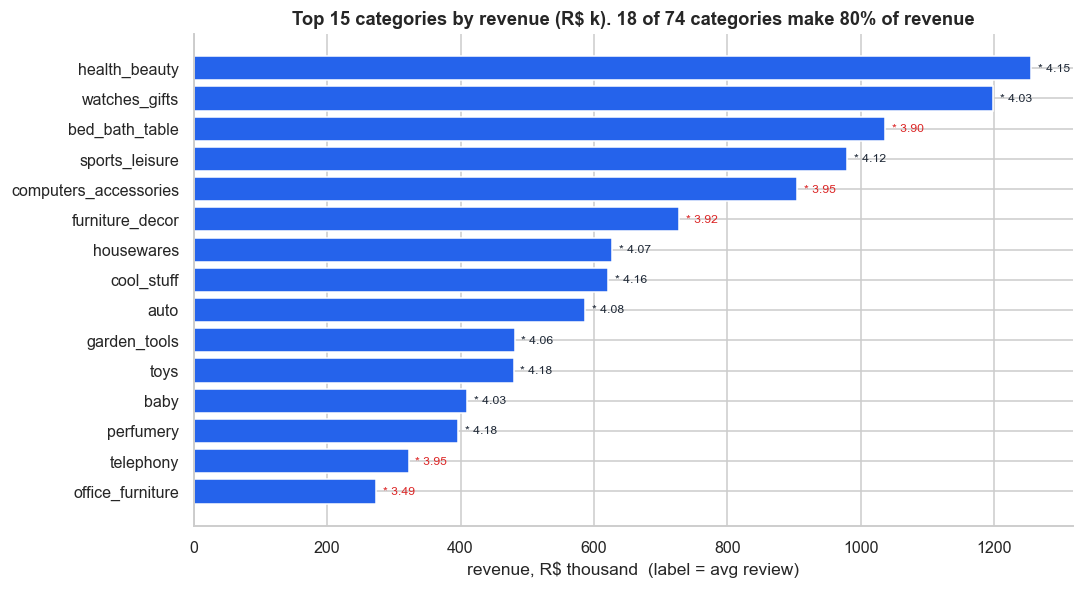

seller_segment
Long tail                  1792
Core                       1186
Star seller                  37
At risk - low rating         23
At risk - late shipping      15
seller_group  pct_revenue
      Top 1%         26.2
     Top 10%         67.5
     Top 20%         82.6
  Bottom 50%          3.2


In [10]:
cat = r("category_performance")
top15 = cat.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(top15.category, top15.revenue / 1e3, color=ACCENT)
for i, (rv_, rev) in enumerate(zip(top15.avg_review, top15.revenue)):
    ax.text(rev / 1e3 + 10, i, f"* {rv_:.2f}", va="center", fontsize=8,
            color=BAD if rv_ < 4 else INK)
n80 = int((cat.cum_pct_revenue <= 80).sum()) + 1
ax.set_title(f"Top 15 categories by revenue (R$ k). {n80} of {len(cat)} categories make 80% of revenue")
ax.set_xlabel("revenue, R$ thousand  (label = avg review)")
save(fig, "09_top_categories")

sel = r("seller_scorecard")
print(sel.seller_segment.value_counts().to_string())
print(r("seller_concentration").to_string(index=False))

## 5. Key findings and recommendations

| # | Finding | Recommendation |
|---|---|---|
| 1 | Revenue grew strongly through 2017 and plateaued in 2018; Nov-2017 Black Friday is the peak month. | Plan capacity and seller stock for Q4; growth now has to come from retention, not just acquisition. |
| 2 | ~97% of customers order once; monthly cohort retention is well under 1%. | Second-order programme: post-delivery coupon, category-based reminders. Even +1pp repeat rate is meaningful revenue. |
| 3 | Late orders average ~2.3 stars vs ~4.3 on time; ~62% of late orders get 1-2 stars. Days late is the strongest driver of negative reviews. | Set realistic delivery estimates, proactive delay notifications, and SLA-based seller ranking. |
| 4 | Orders split across several sellers rate much lower. | Consolidate shipments or warn buyers at checkout. |
| 5 | North/Northeast states have the longest deliveries and lowest ratings; freight is a larger share of the basket there. | Regional fulfilment partners/hubs; freight subsidies for high-value categories. |
| 6 | Top 10% of sellers carry ~2/3 of revenue; a small set of high-volume sellers have low ratings or high late rates. | Seller scorecard with coaching / demotion for "at risk" sellers. |

In [11]:
con.close()
print("Figures saved to", FIG.relative_to(ROOT))

Figures saved to reports\figures
